In [14]:
import pandas as pd

# Load CSV
data = pd.read_csv("data/Indoor Air Pollution Data.csv", low_memory=False)
data.describe()

,NH3,CO,PM2.5,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
count,173465.000000,173465.000000,173465.000000,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.00
mean,0.670185,4.339625,0.057456,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
std,0.177971,1.615590,0.116102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.290000,0.290000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
25%,0.540000,3.610000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
50%,0.650000,4.190000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
75%,0.750000,4.860000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
max,1.630000,9.920000,0.470000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45


In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173468 entries, 0 to 173467
Data columns (total 19 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   NH3          173465 non-null  float64
 1   NO2          173468 non-null  object 
 2   CO           173465 non-null  float64
 3   PM2.5        173465 non-null  float64
 4   Temp         173465 non-null  object 
 5   Pressure     173465 non-null  object 
 6   Humidity     173465 non-null  object 
 7   O3           173465 non-null  object 
 8   Date         173465 non-null  object 
 9   Unnamed: 9   1 non-null       float64
 10  Unnamed: 10  1 non-null       float64
 11  Unnamed: 11  1 non-null       float64
 12  Unnamed: 12  1 non-null       float64
 13  Unnamed: 13  1 non-null       float64
 14  Unnamed: 14  1 non-null       float64
 15  Unnamed: 15  1 non-null       float64
 16  Unnamed: 16  1 non-null       float64
 17  Unnamed: 17  1 non-null       float64
 18  Unnamed: 18  1 non-null 

In [16]:
# Drop unnamed columns
data.drop(columns=[col for col in data.columns if "Unnamed" in col], inplace=True)

In [17]:
data.dropna(inplace=True)
# Remove duplicate rows if any
data = data.drop_duplicates()
# Fix numeric columns with bad characters (like '12.450.73')
for col in data.columns[:-1]:  # skip 'Date' column
    data[col] = data[col].astype(str).str.replace('[^0-9.]', '', regex=True)
    data[col] = data[col].apply(lambda x: x if x.count('.') <= 1 else x.replace('.', '', x.count('.') - 1))  # keep last dot
    data[col] = pd.to_numeric(data[col], errors='coerce')

In [18]:
data = data.set_index('Date')

In [19]:

# Constants
R = 0.08205  # Ideal gas constant in (L·atm)/(mol·K)
MW = {
    'CO': 28.01,    # Carbon Monoxide in ppm
    'NO2': 46.01,   # Nitrogen Dioxide in ppm
    'NH3': 17.03,   # Ammonia in ppm
    'O3': 48.00     # Ozone in ppb
}

# Conversion functions
def ppm_to_ugm3(ppm, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppm * mw * pressure_atm * 1000) / (R * (temp_c + 273.15))

def ppb_to_ugm3(ppb, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppb * mw * pressure_atm) / (R * (temp_c + 273.15))

# Ensure relevant columns are numeric
for col in ['CO', 'NO2', 'NH3', 'O3', 'Temp', 'Pressure']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Apply conversions
data['CO_ugm3'] = ppm_to_ugm3(data['CO'], MW['CO'], data['Temp'], data['Pressure'])
data['NO2_ugm3'] = ppm_to_ugm3(data['NO2'], MW['NO2'], data['Temp'], data['Pressure'])
data['NH3_ugm3'] = ppm_to_ugm3(data['NH3'], MW['NH3'], data['Temp'], data['Pressure'])
data['O3_ugm3'] = ppb_to_ugm3(data['O3'], MW['O3'], data['Temp'], data['Pressure'])


In [20]:
# --- Define EAQI breakpoints for each pollutant (in µg/m³) ---
eaqi_breakpoints = {
    'PM2.5': [
        (0.0, 50.4, 0, 50),
        (50.5, 60.4, 51, 100),
        (60.5, 75.4, 101, 150),
        (75.5, 150.4, 151, 200),
        (150.5, 250.4, 201, 300),
        (250.5, 500.4, 301, 500)
    ],
    'CO_ugm3': [  # Converted from mg/m³ to µg/m³
        (0.0, 5400.0, 0, 50),
        (5401.0, 10400.0, 51, 100),
        (10401.0, 14400.0, 101, 150),
        (14401.0, 17900.0, 151, 200),
        (17901.0, 35400.0, 201, 300),
        (35401.0, 58400.0, 301, 500)
    ],
    'NO2_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ],
    'O3_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ]
}

# --- Function to calculate sub-index for a given pollutant ---
def calculate_eaqi_sub_index(value, breakpoints):
    for BPLo, BPHi, ILo, IHi in breakpoints:
        if BPLo <= value <= BPHi:
            return round(((IHi - ILo) / (BPHi - BPLo)) * (value - BPLo) + ILo)
    return None

# --- Calculate EAQI sub-indices ---
data['EAQI_PM25'] = data['PM2.5'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['PM2.5']))
data['EAQI_CO'] = data['CO_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['CO_ugm3']))
data['EAQI_NO2'] = data['NO2_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['NO2_ugm3']))
data['EAQI_O3'] = data['O3_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['O3_ugm3']))

# --- Final EAQI is the max sub-index across pollutants ---
data['EAQI_Overall'] = data[['EAQI_PM25', 'EAQI_CO', 'EAQI_NO2', 'EAQI_O3']].max(axis=1)

# --- Classify into EAQI categories ---
def classify_eaqi(index_value):
    if pd.isna(index_value):
        return None
    elif index_value <= 50:
        return "Good"
    elif index_value <= 100:
        return "Moderate"
    elif index_value <= 150:
        return "Unhealthy for sensitive groups"
    elif index_value <= 200:
        return "Unhealthy"
    elif index_value <= 300:
        return "Very unhealthy"
    elif index_value <= 500:
        return "Hazardous"
    else:
        return "Out of Range"

data['EAQI_Category'] = data['EAQI_Overall'].apply(classify_eaqi)


In [21]:
# Count each EAQI category
category_counts = data['EAQI_Category'].value_counts().sort_index()

# Format as a table
print("\n📊 EAQI Category Distribution (based on max pollutant per record):\n")
print("| EAQI Category                     | Count     |")
print("|----------------------------------|-----------|")
for category, count in category_counts.items():
    print(f"| {category:<32} | {count:<9} |")


📊 EAQI Category Distribution (based on max pollutant per record):

| EAQI Category                     | Count     |
|----------------------------------|-----------|
| Good                             | 3561      |
| Hazardous                        | 43        |
| Moderate                         | 151223    |
| Unhealthy                        | 2777      |
| Unhealthy for sensitive groups   | 15720     |
| Very unhealthy                   | 141       |


In [22]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
Temp        3526
Pressure    3525
Humidity    3531
CO_ugm3     3526
NO2_ugm3    3526
NH3_ugm3    3526
O3_ugm3     3526
EAQI_CO     3537
EAQI_NO2    3578
EAQI_O3     3612
dtype: int64


In [23]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

  # Replace with your actual file path

# 2. Identify features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
target = 'EAQI_Category'

# 3. Drop columns not needed for training (like EAQI_CO, EAQI_NO2, EAQI_O3)
drop_cols = ['EAQI_CO', 'EAQI_NO2', 'EAQI_O3']
data.drop(columns=[col for col in drop_cols if col in data.columns], inplace=True)

# 4. Check missing values
print("Missing value count:\n", data[features + [target]].isnull().sum())

# 5. Drop rows where target is missing (classification label must be known)
data = data.dropna(subset=[target])

# 6. Impute missing feature values with mean
imputer = SimpleImputer(strategy='mean')
data[features] = imputer.fit_transform(data[features])



# 8. Check if it worked
print("\n✅ Final check: No missing values?\n", data.isnull().sum().sum() == 0)
print("🟢 Class distribution after cleaning:\n", data[target].value_counts())


Missing value count:
 PM2.5               0
CO_ugm3          3526
NO2_ugm3         3526
NH3_ugm3         3526
O3_ugm3          3526
Temp             3526
Humidity         3531
Pressure         3525
EAQI_Category       0
dtype: int64

✅ Final check: No missing values?
 True
🟢 Class distribution after cleaning:
 EAQI_Category
Moderate                          151223
Unhealthy for sensitive groups     15720
Good                                3561
Unhealthy                           2777
Very unhealthy                       141
Hazardous                             43
Name: count, dtype: int64


In [25]:
# iaq_model_training_balanced.py

import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 1. Load your data


# 2. Subsample 'Moderate' class to 10,000 rows
balanced_data = (
    pd.concat([
        data[data['EAQI_Category'] == 'Moderate'].sample(n=10000, random_state=42),
        data[data['EAQI_Category'] != 'Moderate']
    ])
    .sample(frac=1, random_state=42)  # Shuffle the rows
)

# 3. Prepare features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = balanced_data[features]
y = balanced_data['EAQI_Category']

# 4. Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 5. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 6. Build pipeline: SMOTE + Scaling + Classifier
pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# 7. Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# 8. Train final model
pipeline.fit(X_train, y_train)

# 9. Evaluate
y_pred = pipeline.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 10. Save model and encoder
joblib.dump(pipeline, "best_model_pipeline01.pkl")
joblib.dump(le, "label_encoder01.pkl")


CV Macro F1: 0.9977 ± 0.0045

Classification Report:

                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00       712
                     Hazardous       1.00      0.89      0.94         9
                      Moderate       1.00      1.00      1.00      2000
                     Unhealthy       1.00      1.00      1.00       556
Unhealthy for sensitive groups       1.00      1.00      1.00      3144
                Very unhealthy       0.97      1.00      0.98        28

                      accuracy                           1.00      6449
                     macro avg       0.99      0.98      0.99      6449
                  weighted avg       1.00      1.00      1.00      6449



['label_encoder01.pkl']

Balanced training data distribution:
 EAQI_Grouped
Low       123827
Medium    123827
High      123827
Name: count, dtype: int64

Classification Report:

              precision    recall  f1-score   support

        High       1.00      1.00      1.00        37
         Low       1.00      1.00      1.00     30957
      Medium       1.00      1.00      1.00      3699

    accuracy                           1.00     34693
   macro avg       1.00      1.00      1.00     34693
weighted avg       1.00      1.00      1.00     34693



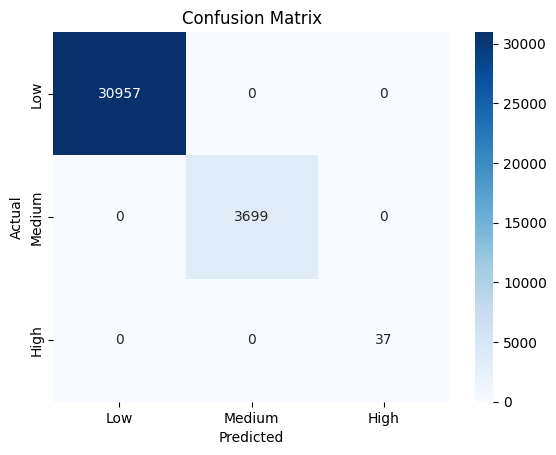

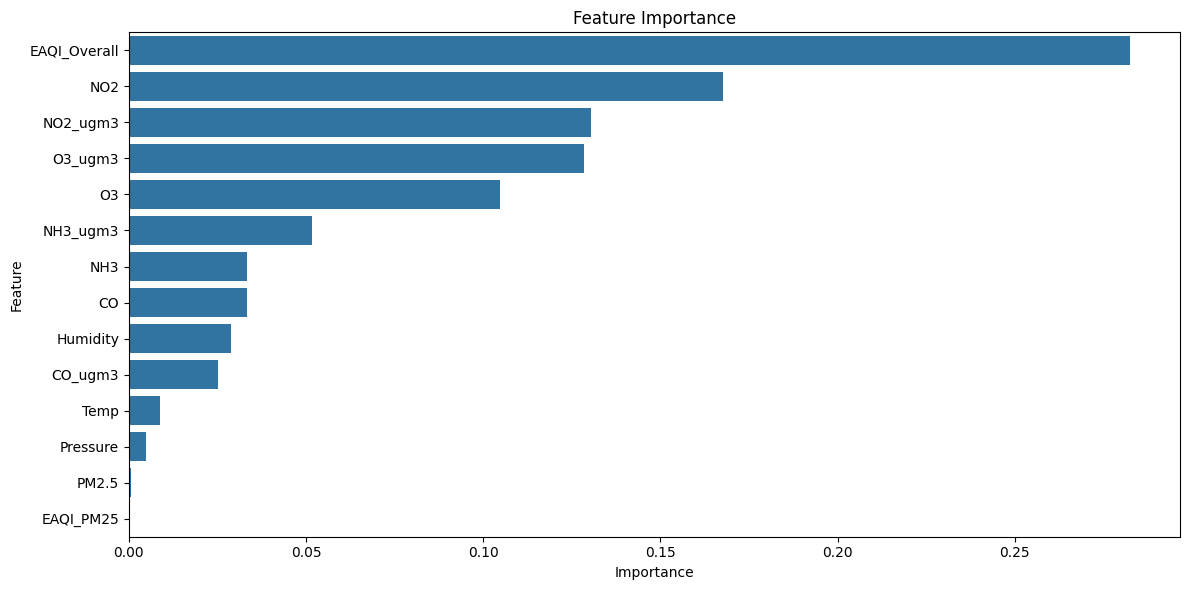

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# Step 1: Group EAQI categories
# -----------------------------
def group_eaqi(cat):
    if cat in ['Good', 'Moderate']:
        return 'Low'
    elif cat in ['Unhealthy', 'Unhealthy for sensitive groups']:
        return 'Medium'
    else:
        return 'High'

data['EAQI_Grouped'] = data['EAQI_Category'].apply(group_eaqi)

# --------------------------------
# Step 2: Prepare features & target
# --------------------------------
# Drop non-numeric, identifier, and target columns
drop_cols = ['EAQI_Category', 'EAQI_Grouped']
X = data.drop(columns=drop_cols, errors='ignore')
y = data['EAQI_Grouped']

# ---------------------------------
# Step 3: Train-Test split (stratify)
# ---------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# -----------------------------
# Step 4: Apply SMOTE on train set
# -----------------------------
sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)

print("Balanced training data distribution:\n", y_train_bal.value_counts())

# -------------------------
# Step 5: Train RandomForest
# -------------------------
clf = RandomForestClassifier(class_weight='balanced', random_state=42)
clf.fit(X_train_bal, y_train_bal)

# ------------------------
# Step 6: Make Predictions
# ------------------------
y_pred = clf.predict(X_test)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# ------------------------
# Step 7: Confusion Matrix
# ------------------------
labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test, y_pred, labels=labels)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# ------------------------
# Step 8: Feature Importance
# ------------------------
importances = pd.Series(clf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=importances, y=importances.index)
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [29]:
print("Train Accuracy:", clf.score(X_train_bal, y_train_bal))
print("Test Accuracy:", clf.score(X_test, y_test))


Train Accuracy: 1.0
Test Accuracy: 1.0


In [30]:
import joblib

# Save model and features
joblib.dump(clf, "rf_eaqi_model.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")


['feature_names.pkl']


Classification Report:

              precision    recall  f1-score   support

        High       1.00      1.00      1.00        37
         Low       1.00      1.00      1.00     30957
      Medium       1.00      1.00      1.00      3699

    accuracy                           1.00     34693
   macro avg       1.00      1.00      1.00     34693
weighted avg       1.00      1.00      1.00     34693



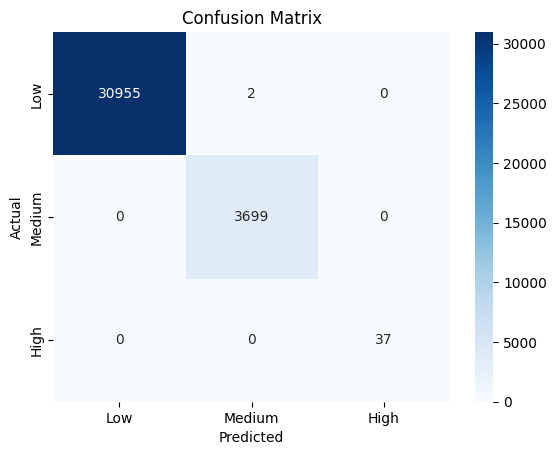

✅ Model and features saved for Streamlit app.


In [33]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

# -----------------------
# Step 1: Define features
# -----------------------

# Only use raw pollutant and environmental columns (no *_ugm3 or EAQI)
selected_features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']

# Optional: add 'Humidity' or 'SO2' if available in your dataset
for col in selected_features:
    if col not in data.columns:
        print(f"⚠️ Warning: '{col}' not found in dataset.")

# -----------------------
# Step 2: Define inputs
# -----------------------
X = data[selected_features]
y = data['EAQI_Grouped']  # This should already be created using the grouped function

# -----------------------
# Step 3: Train-test split
# -----------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42
)

# -----------------------
# Step 4: Balance with SMOTE
# -----------------------
sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)

# -----------------------
# Step 5: Train model
# -----------------------
clf = RandomForestClassifier(class_weight='balanced', random_state=42)
clf.fit(X_train_bal, y_train_bal)

# -----------------------
# Step 6: Evaluate model
# -----------------------
y_pred = clf.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# -----------------------
# Step 7: Save model
# -----------------------
joblib.dump(clf, 'rf_eaqi_model.pkl')
joblib.dump(selected_features, 'feature_names.pkl')
print("✅ Model and features saved for Streamlit app.")
